## Train SRU model with embeddings-resnet50-100

Hope it will work...

### Installing SRU with v3.0.0

In [1]:
!pip install sru==3.0.0.dev6

### Importing Necessary Libraries

In [2]:
import logging
import os

import numpy as np
import torch
from sklearn.model_selection import train_test_split
from sru import SRUpp
from torch.nn import CrossEntropyLoss
from torch.nn import Module, Dropout, Linear
from torch.optim import Adam
from torch.utils.data import TensorDataset, DataLoader
from tqdm import tqdm
import gc

### Set the Device to CUDA

In [3]:
# Set the device to use (e.g., 'cpu', 'cuda', 'mps')
device = torch.device("mps" if torch.backends.mps.is_available() else
                      ("cuda" if torch.cuda.is_available() else "cpu"))

# Select Device According to Availability
print("Device selected:", device)

# If the device is CUDA, print the device capability
if device.type == "cuda":
    os.system("nvidia-smi")
    print()
    print("Device type:", device.type)
    print("Capability:", torch.cuda.get_device_capability(device))
else:
    print("Device capabilities are limited on MPSs and CPUs.")


Device selected: cuda
Tue Apr  2 05:19:28 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.129.03             Driver Version: 535.129.03   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  Tesla P100-PCIE-16GB           Off | 00000000:00:04.0 Off |                    0 |
| N/A   36C    P0              28W / 250W |      2MiB / 16384MiB |      0%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+---

In [4]:
embedding_file = np.load('/kaggle/input/resnet-embeddings-7000-150-2048/train_embeddings.npy')
print(embedding_file.shape)
label_file = np.load('/kaggle/input/resnet-embeddings-7000-150-2048/train_labels.npy')
print(label_file.shape)

(7000, 150, 2048)
(7000,)


In [5]:
inference_sample_size = 0.05
test_sample_size = 0.2

In [6]:
# Inference split
embedding, inference_sample_embedding, labels, inference_sample_label = train_test_split(
    embedding_file, label_file, test_size=inference_sample_size, random_state=42
)

# Train Test Split
x_train, x_test, y_train, y_test = train_test_split(
    embedding, labels, test_size=test_sample_size, random_state=42
)

In [7]:
train_embeddings = torch.from_numpy(x_train).to(device)
train_labels = torch.from_numpy(y_train).to(device)
test_embeddings = torch.from_numpy(x_test).to(device)
test_labels = torch.from_numpy(y_test).to(device)
inference_embeddings = torch.from_numpy(inference_sample_embedding).to(device)
inference_labels = torch.from_numpy(inference_sample_label).to(device)

In [8]:
# Delete initial file variables
del embedding_file
del label_file

# Delete 2nd order variables (splitting)
del embedding
del labels
del inference_sample_embedding
del inference_sample_label
del x_train
del x_test
del y_train
del y_test

In [9]:
batch_size = 8

# Create TensorDataset
train_data = TensorDataset(train_embeddings, train_labels)
test_data = TensorDataset(test_embeddings, test_labels)
inference_data = TensorDataset(inference_embeddings, inference_labels)

train_loader = DataLoader(train_data, shuffle=True, batch_size=batch_size)
test_loader = DataLoader(test_data, shuffle=True, batch_size=batch_size)
inference_loader = DataLoader(inference_data, shuffle=True, batch_size=batch_size)

### Train Test Split, Convert to torch.tensor and View Shape

In [10]:
class SRUppModel(Module):
    def __init__(self, input_size, hidden_size, **kwargs):
        super(SRUppModel, self).__init__()
        # Main SRU layer
        self.sru_layers = SRUpp(
            proj_size = 2048,
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=kwargs.get('num_layers', 2),
            dropout=kwargs.get('dropout_prob', 0.0),
            bidirectional=kwargs.get('bidirectional', False),
            layer_norm=kwargs.get('layer_norm', True),
            highway_bias=kwargs.get('highway_bias', 0.0),
            rescale=kwargs.get('rescale', True),
            nn_rnn_compatible_return=kwargs.get('nn_rnn_compatible_return', False),
            proj_input_to_hidden_first=kwargs.get('proj_input_to_hidden_first', False),
            normalize_after=kwargs.get('normalize_after', False),
        ).to(device)
        # Dropout layer
        self.dropout = Dropout(kwargs.get('dropout_layer_prob', 0.2)).to(device)
        # Linear layer (Fully connected layer)
        self.linear = Linear(
            hidden_size, 
            out_features=kwargs.get('num_classes', 2)
        ).to(device)
        # L2 regularization
        self.l2_reg_lambda = kwargs.get('l2_reg_lambda', 1e-5)

    def forward(self, x):
        output_states, _, _ = self.sru_layers(x)
        output = self.linear(self.dropout(output_states[-1]))
        return output, output_states

    def l2_regularization(self):
        l2_reg = torch.tensor(0., device=device)
        for param in self.parameters():
            l2_reg += torch.norm(param, p=2)
        return self.l2_reg_lambda * l2_reg


model = SRUppModel(2048, 1024)
model = model.to(device)
model

SRUppModel(
  (sru_layers): SRUpp(
    (rnn_lst): ModuleList(
      (0): SRUppCell(2048, 1024, rescale=True, layer_norm=True, normalize_after=False,
        transform_module=SRUppAttention(
        (dropout): Dropout(p=0.0, inplace=False)
        (linear1): Linear(in_features=2048, out_features=2048, bias=False)
        (linear2): Linear(in_features=2048, out_features=4096, bias=False)
        (linear3): Linear(in_features=2048, out_features=4096, bias=False)
        (layer_norm): LayerNorm((2048,), eps=1e-05, elementwise_affine=True)
      )
      )
      (1): SRUppCell(1024, 1024, rescale=True, layer_norm=True, normalize_after=False,
        transform_module=SRUppAttention(
        (dropout): Dropout(p=0.0, inplace=False)
        (linear1): Linear(in_features=1024, out_features=2048, bias=False)
        (linear2): Linear(in_features=2048, out_features=4096, bias=False)
        (linear3): Linear(in_features=2048, out_features=3072, bias=False)
        (layer_norm): LayerNorm((2048,), 

In [11]:
# Define your loss function and optimizer
criterion = CrossEntropyLoss()
optimizer = Adam(model.parameters())

In [12]:
# class CreateCluster:
#     def __init__(self):
#         # Define Clusters
#         self.normal = []
#         self.arson = []
#         self.abuse = []
#         self.assault = []
#         self.burglary = []
#         self.explosion = []
#         self.fighting = []
#         self.roadAccident = []
#         self.robbery = []
#         self.shooting = []
#         self.stealing = []
#         self.vandalism = []

#         # Define Centers
#         self.centers = []

#     def add(self, embedding, label: int):
#         if label == 0:
#             self.normal.append(embedding)
#         elif label == 2:
#             self.arson.append(embedding)
#         elif label == 1:
#             self.abuse.append(embedding)
#         elif label == 3:
#             self.assault.append(embedding)
#         elif label == 5:
#             self.burglary.append(embedding)
#         elif label == 6:
#             self.explosion.append(embedding)
#         elif label == 7:
#             self.fighting.append(embedding)
#         elif label == 4:
#             self.roadAccident.append(embedding)
#         elif label == 8:
#             self.robbery.append(embedding)
#         elif label == 9:
#             self.shooting.append(embedding)
#         elif label == 10:
#             self.stealing.append(embedding)
#         elif label == 11:
#             self.vandalism.append(embedding)
        
        
#     def __repr__(self):
#         return f'Normal: {len(self.normal)}, Arson: {len(self.arson)}, Abuse: {len(self.abuse)}, Assault: {len(self.assault)}, Burglary: {len(self.burglary)}, Explosion: {len(self.explosion)}, Fighting: {len(self.fighting)}, Road Accident: {len(self.roadAccident)}, Robbery: {len(self.robbery)}, Shooting: {len(self.shooting)}, Stealing: {len(self.stealing)}, Vandalism: {len(self.vandalism)}'
    

In [13]:
class CreateCluster:
    def __init__(self):
        # Define Clusters
        self.nonanomalous = []
        self.anomalous = []

        # Define Centers
        self.centers = []

    def add(self, embedding, label: int):
        if label == 0:
            self.nonanomalous.append(embedding)
        elif label == 1:
            self.anomalous.append(embedding)
        
        
    def __repr__(self):
        return f'Nonanomalous: {len(self.nonanomalous)}, Anomalous: {len(self.anomalous)}'
    

In [14]:
# create cluster

cluster = CreateCluster()

model.train()
epochs = 100

total_correct_all_epochs = 0
total_samples_all_epochs = 0

# Setup logging
logging.basicConfig(filename='training.log', level=logging.INFO)

for epoch in range(epochs):
    total_correct = 0
    total_samples = 0
    total_loss = 0.0

    # Create tqdm progress bar for training loader
    progress_bar = tqdm(enumerate(train_loader), desc=f"Epoch {epoch + 1}/{epochs}", total=len(train_loader))

    for i, (videos, labels) in progress_bar:
#         print(videos.shape)  #torch.Size([8, 150, 2048])
        videos = videos.permute(1, 0, 2)
#         print(cluster_video.shape) 
        # Forward pass
        # (100, 8, 2048)
        outputs, temporal_features = model(videos)
        labels = labels.long()  # Convert labels to Long type
        
#         print(outputs.shape, embedding.shape)
        
        # Put output into cluster with label when epoch = epochs
        if epoch == 99:
            temporal_features = temporal_features.permute(1, 0, 2)
            for temp_f, label in zip(temporal_features, labels):
                l = label.item()
                # Add embedding and label to cluster one by one
#                 print(temp_f.shape)
                temp_f = temp_f.reshape(temp_f.shape[0]*temp_f.shape[1])
#                 print(temp_f.shape)
                cluster.add(temp_f, l)        
        
        loss = criterion(outputs, labels) + model.l2_regularization()  # calculates loss
        total_loss += loss.item()
        # Backward and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        # Calculate accuracy per batch
        _, predicted = torch.max(outputs.data, 1)
        total_samples += labels.size(0)
        total_correct += (predicted == labels).sum().item()
        batch_accuracy = 100 * total_correct / total_samples

        # Update progress bar
        progress_bar.set_postfix(loss=loss.item(), accuracy=batch_accuracy)
        
        # Update overall accuracy counters
        total_correct_all_epochs += total_correct
        total_samples_all_epochs += total_samples
        
    # Log epoch statistics
    epoch_loss = total_loss / len(train_loader)
    epoch_accuracy = 100 * total_correct / total_samples
    logging.info(f'Epoch [{epoch + 1}/{epochs}], Loss: {epoch_loss}, Accuracy: {epoch_accuracy}%')

    print(f'Epoch [{epoch + 1}/{epochs}], Loss: {epoch_loss}, Accuracy: {epoch_accuracy}%')

# Close logging
logging.shutdown()

overall_accuracy = 100 * total_correct_all_epochs / total_samples_all_epochs
print(f'Average Train Accuracy of the model on the train videos: {overall_accuracy}%')

Epoch 1/100: 100%|██████████| 665/665 [00:38<00:00, 17.19it/s, accuracy=75.7, loss=0.807]


Epoch [1/100], Loss: 0.7024195892456219, Accuracy: 75.71428571428571%


Epoch 2/100: 100%|██████████| 665/665 [00:37<00:00, 17.59it/s, accuracy=83.1, loss=0.172]


Epoch [2/100], Loss: 0.3889749287438572, Accuracy: 83.1203007518797%


Epoch 3/100: 100%|██████████| 665/665 [00:37<00:00, 17.60it/s, accuracy=84.4, loss=0.0352]


...

Epoch [98/100], Loss: 0.05139442281447407, Accuracy: 99.04135338345864%


Epoch 99/100: 100%|██████████| 665/665 [00:37<00:00, 17.52it/s, accuracy=99.4, loss=0.0101]


Epoch [99/100], Loss: 0.028732064467175564, Accuracy: 99.4172932330827%


Epoch 100/100: 100%|██████████| 665/665 [00:38<00:00, 17.24it/s, accuracy=98.8, loss=0.0663]


Epoch [100/100], Loss: 0.0552357383002352, Accuracy: 98.8157894736842%
Average Train Accuracy of the model on the train videos: 96.45431371220845%


In [15]:
# print(cluster)
import torch

center = []

nonanomalous = [tensor.cpu().detach().numpy() for tensor in cluster.nonanomalous]
anomalous = [tensor.cpu().detach().numpy() for tensor in cluster.anomalous]

center.append(np.mean(nonanomalous, axis=0))
center.append(np.mean(anomalous, axis=0))

In [16]:
train_embedding = np.concatenate((nonanomalous, anomalous), axis=0)

train_labels = []

for i in range(len(nonanomalous)):
    train_labels.append(0)
    
for i in range(len(anomalous)):
    train_labels.append(1)
    
train_labels = np.array(train_labels)


len(train_embedding), len(train_labels)

(5320, 5320)

In [17]:
model.eval()

ttf = []
ttl = []

with torch.no_grad():
    correct = 0
    total = 0
    for videos, labels in test_loader:
        videos = videos.permute(1, 0, 2)
        outputs, t = model(videos)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        
        t = t.permute(1, 0, 2)
#         print(t.shape)
        for v, l in zip(t, labels):
            v = v.reshape(-1)
            l = l.item()
#             print(v.shape)
            ttf.append(v)
            ttl.append(l)
        #print test accuracy per test

    print(f'Test Accuracy of the model on the test videos: {100 * correct / total}%')


Test Accuracy of the model on the test videos: 96.16541353383458%


In [18]:
ttf = [tensor.cpu().detach().numpy() for tensor in ttf]

In [19]:
from sklearn.metrics.pairwise import cosine_similarity

category_names = ["Anomalous", "Nonanomalous"]

def cosine_similarity_with_centers(embedding, center):
    similarities = [cosine_similarity([embedding], [c])[0][0] for c in center]
    return similarities

def predict_cluster(embedding, center):
    similarities = cosine_similarity_with_centers(embedding, center)
    max_similarity_index = np.argmax(similarities)
    return max_similarity_index

count = 0

# Loop through each embedding-label pair
for emb, label in zip(ttf, ttl):
#     emb = emb.reshape(emb.shape[0]*emb.shape[1])
    predicted_cluster_index = predict_cluster(emb, center)
    if predicted_cluster_index == label:
        count = count+1
print(count)

1269


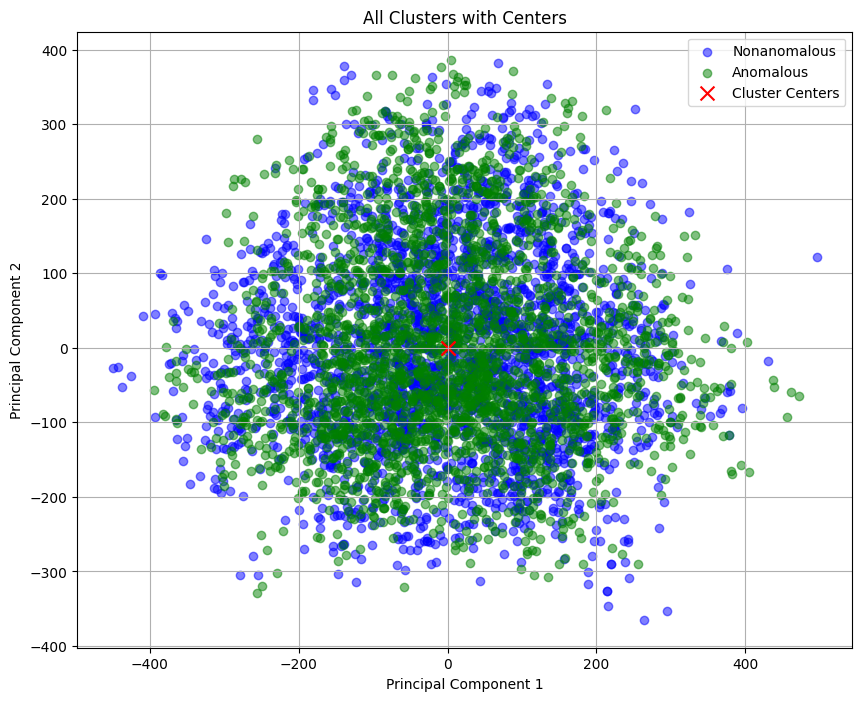

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Assuming centers and category_lists are already defined

# Convert centers to numpy array
centers_np = np.array([c for c in center if center is not None])

# Define a list of labels for each category
category_labels = ['Nonanomalous', 'Anomalous']

# Create a list to store embeddings for each category
category_embeddings = []

# Convert category lists to numpy arrays and store them in category_embeddings
for label in range(len(category_labels)):
    embeddings = np.array([emb.cpu().detach().numpy() for emb, l in zip(train_embeddings, train_labels) if l == label])
    category_embeddings.append(embeddings)

# Apply normalization to each category's embeddings
normalized_embeddings = [StandardScaler().fit_transform(embeddings.reshape(embeddings.shape[0], -1)) for embeddings in category_embeddings]

# Apply PCA for dimensionality reduction
pca = PCA(n_components=2)
embeddings_2d = [pca.fit_transform(embeddings) for embeddings in normalized_embeddings]

# Create a list to store colors for each category
colors = ['b', 'g']

# Plot clusters and centers
plt.figure(figsize=(10, 8))
for i, embeddings in enumerate(embeddings_2d):
    plt.scatter(embeddings[:, 0], embeddings[:, 1], label=category_labels[i], alpha=0.5, color=colors[i])
if len(centers_np) > 0:
    plt.scatter(centers_np[:, 0], centers_np[:, 1], marker='x', color='red', s=100, label='Cluster Centers')
plt.title('All Clusters with Centers')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True)
plt.show()
